# Phân tích HPO và Pareto cho Random Forest

**Môn:** Nhập môn Tối ưu hóa  
**Sinh viên:** Dương Quốc Trọng - 2274802010932  

Notebook này đọc các kết quả CSV do `python run_project.py` tạo ra. Để chạy lại toàn bộ thực nghiệm (Grid Search, Random Search, TPE và NSGA-II), hãy chạy lệnh trên từ thư mục gốc trước khi chạy các cell phân tích.

> Test set đã được khóa trong quá trình tuning. Các bảng `final_model_metrics.csv` là kết quả đánh giá cuối sau khi cấu hình đã được chọn bằng development CV.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

print("Project folder:", ROOT.resolve())
print("Results folder exists:", RESULTS.exists())

Project folder: /mnt/data/rf_hpo_pareto_project
Results folder exists: True


## 1. So sánh ba phương pháp HPO

Mỗi phương pháp có 24 trial cho mỗi seed, lặp với ba seed. Điểm được tính bằng mean accuracy trên 5 fold.

In [2]:
method_summary = pd.read_csv(RESULTS / "search_method_summary.csv")
method_summary.round(4)

,method,best_cv_accuracy_mean,best_cv_accuracy_std,search_time_mean_sec,search_time_std_sec,evaluations_per_seed,total_evaluations
0,Grid Search,0.9648,0.0022,6.1064,0.1142,24.0,72
1,Random Search,0.9648,0.0022,6.3176,0.0487,24.0,72
2,Optuna TPE,0.9641,0.0025,7.3615,0.2286,24.0,72


## 2. Theo dõi quá trình tìm kiếm

`best_so_far` cho biết điểm validation tốt nhất mà phương pháp đã tìm thấy sau từng trial. Đường cong càng sớm đạt vùng cao thường cho thấy việc sử dụng evaluation budget hiệu quả hơn.

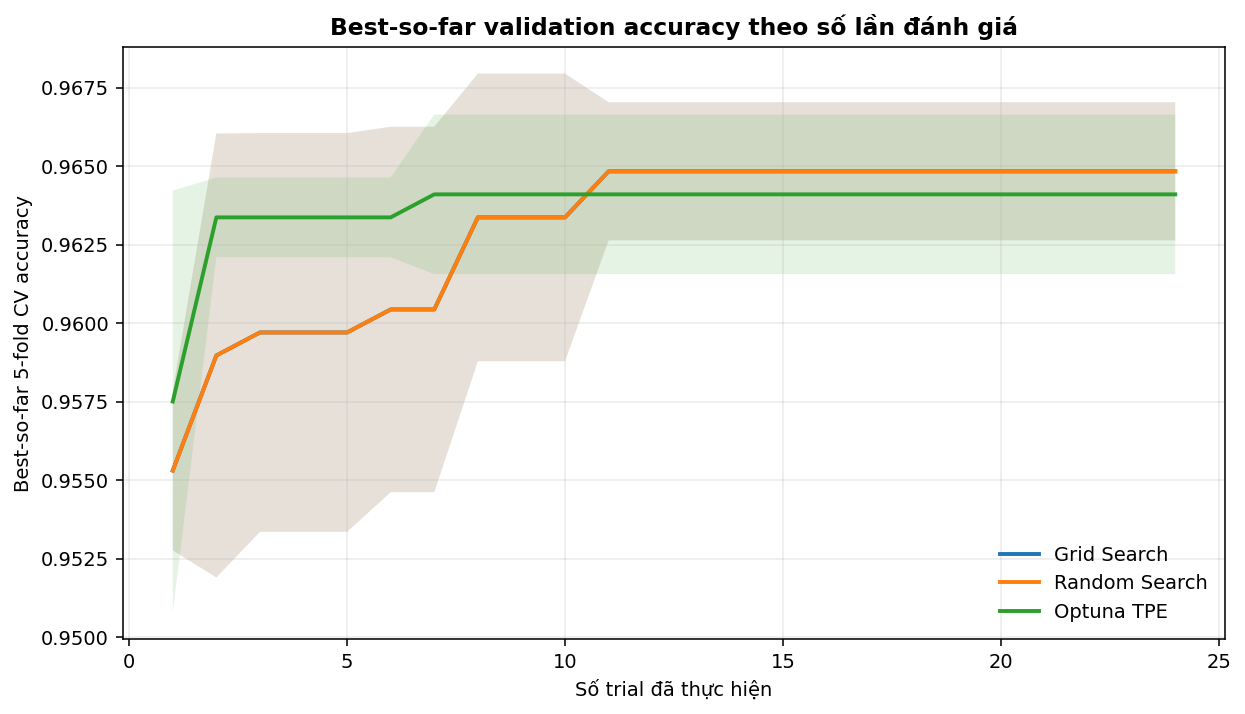

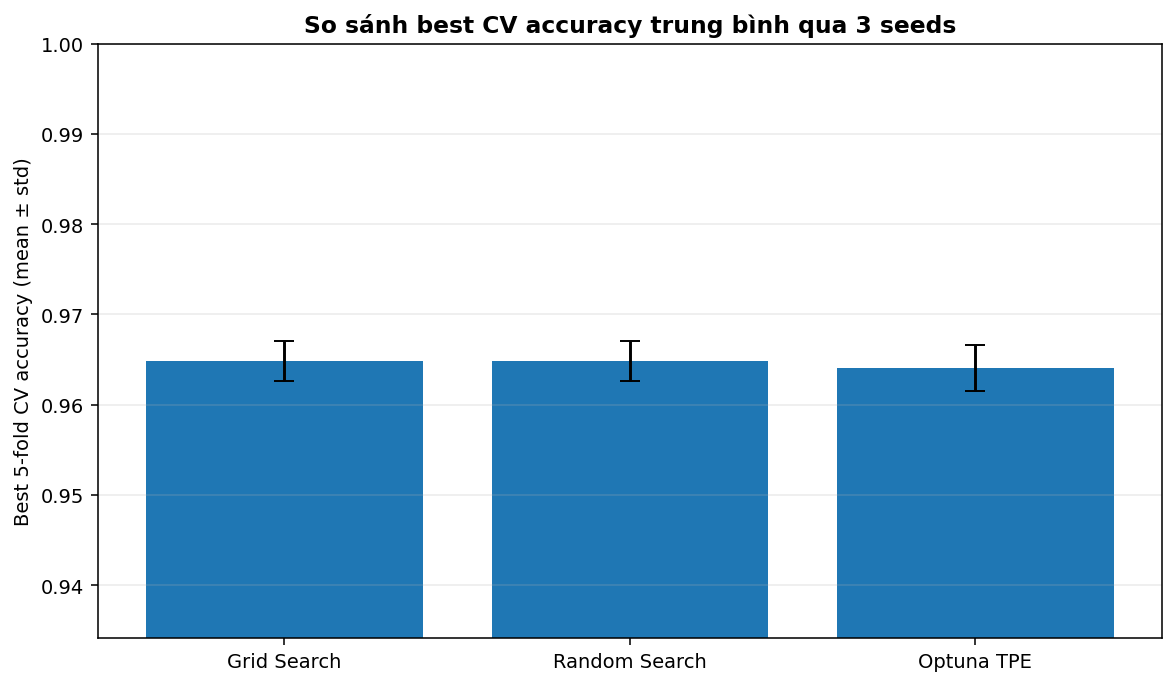

In [3]:
from IPython.display import Image, display

display(Image(filename=str(FIGURES / "01_best_so_far.png")))
display(Image(filename=str(FIGURES / "04_method_comparison.png")))

## 3. Kết quả đa mục tiêu NSGA-II

Accuracy cần tối đa hóa; latency và tổng node cần tối thiểu hóa. Các cấu hình không bị cấu hình khác dominate tạo thành Pareto front.

In [4]:
pareto = pd.read_csv(RESULTS / "pareto_front.csv")
pareto[["trial", "cv_accuracy", "latency_median_ms", "latency_p95_ms", "total_nodes", "distance_to_ideal"]].sort_values("cv_accuracy", ascending=False).round(4)

,trial,cv_accuracy,latency_median_ms,latency_p95_ms,total_nodes,distance_to_ideal
1,7,0.9604,1.9311,2.3545,1038,1.4102
5,20,0.9582,1.7994,1.9410,1042,1.3276
3,13,0.9560,0.9471,1.1943,552,0.3733
2,8,0.9538,1.1065,1.3391,512,0.4431
0,5,0.9495,0.9680,1.0876,418,0.5665
4,14,0.9407,1.0238,1.5130,342,1.0030


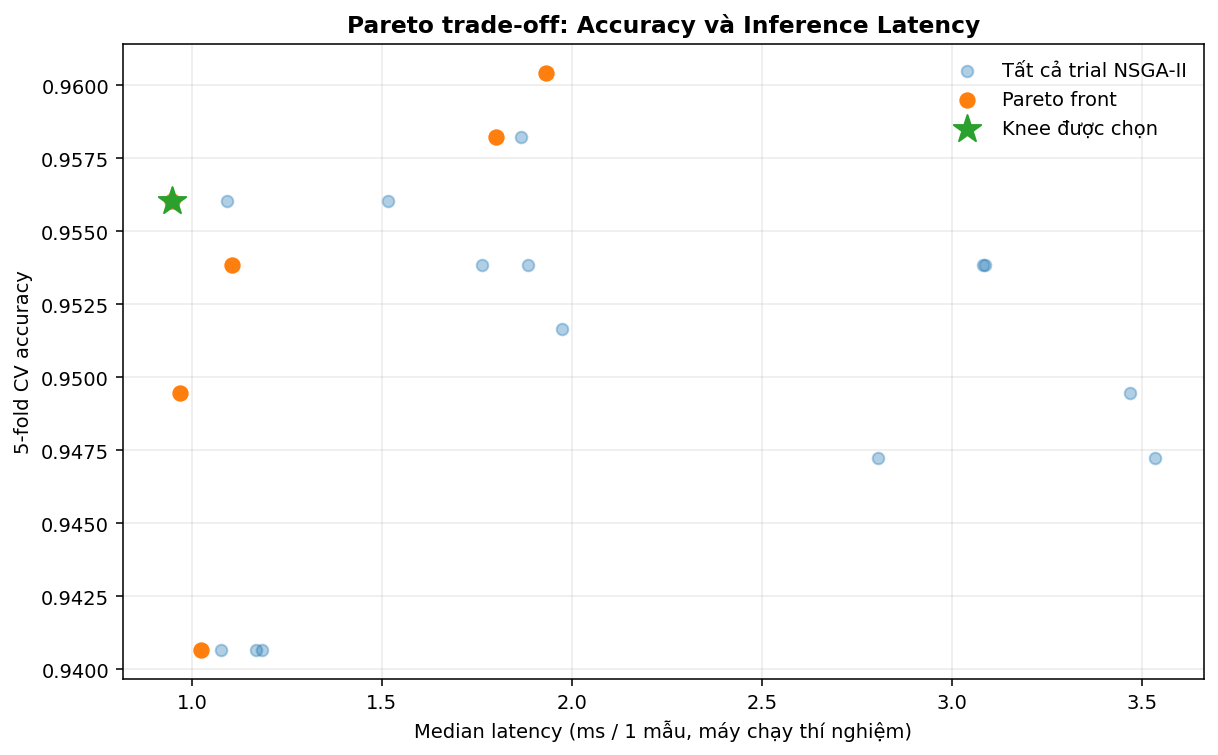

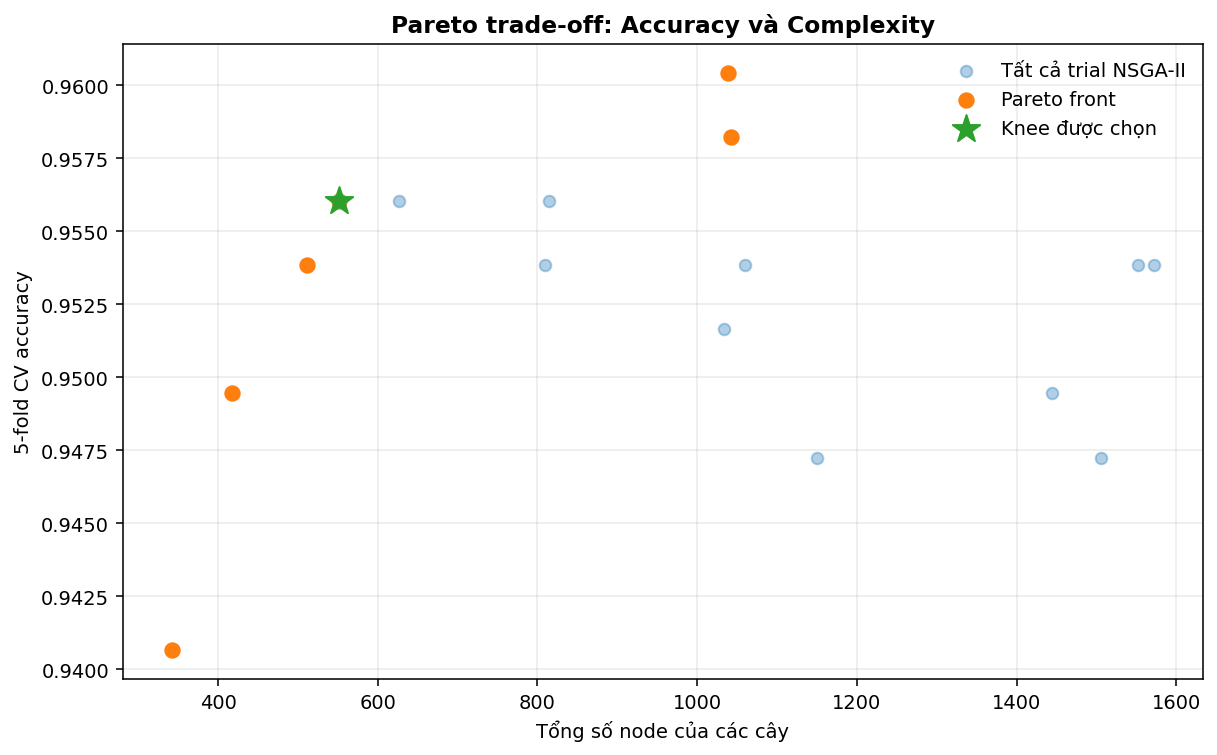

In [5]:
display(Image(filename=str(FIGURES / "02_pareto_accuracy_latency.png")))
display(Image(filename=str(FIGURES / "03_pareto_accuracy_complexity.png")))

## 4. Đánh giá cuối trên test set

Bảng này chỉ được tạo sau khi đã khóa các cấu hình bằng CV. Không dùng các metric test để chọn lại hyperparameter.

In [6]:
final_metrics = pd.read_csv(RESULTS / "final_model_metrics.csv")
final_metrics[["model", "test_accuracy", "test_f1", "test_roc_auc", "latency_median_ms", "latency_p95_ms", "total_nodes", "model_size_mb"]].round(4)

,model,test_accuracy,test_f1,test_roc_auc,latency_median_ms,latency_p95_ms,total_nodes,model_size_mb
0,Baseline mặc định,0.9561,0.9655,0.9937,4.2436,5.4143,3556,0.3093
1,Best HPO (CV cao nhất),0.9561,0.9655,0.9942,1.7849,2.2009,1392,0.1222
2,Pareto knee (NSGA-II),0.9474,0.9583,0.9901,0.9695,1.2285,552,0.0511


## 5. Kết luận

- Grid và Random có kết quả gần như trùng nhau vì Random đã lấy đủ 24 cấu hình của search space hữu hạn.
- TPE có thể tận dụng lịch sử trial, nhưng với budget nhỏ và không gian categorical ngắn, không bảo đảm luôn thắng.
- Pareto front giúp nhìn thấy các cấu hình đánh đổi. Điểm cuối được chọn tùy yêu cầu Cloud/Edge/Real-time, không chỉ dựa vào accuracy.
- Latency phụ thuộc môi trường phần cứng và workload; cần đo lại trên thiết bị thực tế khi triển khai.

**Muốn chạy lại tất cả thí nghiệm:** mở Terminal tại thư mục gốc và chạy `python run_project.py`.